# DBM301 – Assignment 2 – Đề 2
**Nhóm:** Group 3 
**Thành viên:** Hưng, Thắng, Quốc Anh, Phú

Notebook này là khung mẫu. Giữ cách đánh số Phần 1–6, thêm ô mã và ô giải thích tuỳ ý. Khi nộp, notebook phải chạy lại từ đầu đến cuối (Restart & Run All) trong tối đa 15 phút, chỉ đọc các tệp dữ liệu của đề.

## Chuẩn bị môi trường
Import thư viện, cố định seed, xác định thư mục dữ liệu và khai báo các hàm đọc/kiểm tra dữ liệu.

In [38]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED=42
np.random.seed(SEED)
TARGET='other vegetables'
EXPECTED_TRAIN=8300
EXPECTED_TEST=1535
ROOTS=[Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT=next((p for p in ROOTS if (p/'data'/'raw'/'groceries_train.csv').is_file()),None)
if PROJECT_ROOT is None and (Path.cwd()/'groceries_train.csv').is_file():
    PROJECT_ROOT=Path.cwd()
if PROJECT_ROOT is None:
    raise FileNotFoundError('Không tìm thấy dữ liệu được cấp. Cần groceries_train.csv trong data/raw/ hoặc cùng thư mục notebook.')
DATA_DIR=PROJECT_ROOT/'data'/'raw'
if not (DATA_DIR/'groceries_train.csv').is_file():
    DATA_DIR=PROJECT_ROOT
OUTPUT_DIR=PROJECT_ROOT

def parse_items(value):
    if not isinstance(value,str) or not value.strip():
        raise ValueError('items phải là chuỗi không rỗng.')
    items=[token.strip() for token in value.split(';')]
    if any(not item for item in items):
        raise ValueError('items có token rỗng hoặc dấu phân cách lặp.')
    if len(items)!=len(set(items)):
        raise ValueError('Một giỏ có món lặp; dừng để kiểm tra dữ liệu gốc.')
    return items

def load_split(filename,expected_rows):
    path=DATA_DIR/filename
    if not path.is_file():
        raise FileNotFoundError(f'Không tìm thấy tệp được cấp: {path}')
    frame=pd.read_csv(path)
    if list(frame.columns)!=['basket_id','items']:
        raise ValueError(f'{filename}: schema phải là basket_id, items.')
    if len(frame)!=expected_rows or frame.isna().any().any():
        raise ValueError(f'{filename}: số dòng hoặc dữ liệu thiếu không hợp lệ.')
    if frame['basket_id'].duplicated().any():
        raise ValueError(f'{filename}: basket_id bị trùng.')
    frame=frame.copy()
    frame['items_list']=frame['items'].map(parse_items)
    frame['basket_size']=frame['items_list'].map(len)
    return frame

def item_matrix(baskets,vocabulary):
    columns={item:index for index,item in enumerate(vocabulary)}
    matrix=np.zeros((len(baskets),len(vocabulary)),dtype=bool)
    for row,basket in enumerate(baskets):
        for item in basket:
            matrix[row,columns[item]]=True
    return matrix

## 1. Tìm hiểu và chuẩn bị dữ liệu

### 1a. Tách giao dịch, ma trận nhị phân và EDA
Tách `items` theo dấu chấm phẩy, tạo ma trận giỏ × món Boolean. Sau đó thống kê từ vựng và kích thước giỏ, xem 20 món phổ biến nhất và biểu đồ đuôi dài. Kích thước test chỉ tính các món còn quan sát được sau khi target bị xóa.

,split,baskets,distinct_items,mean_size,median_size,min_size,q25,q75,max_size
0,train,8300,168,4.244,3.0,1,1.0,6.0,29
1,test_visible_after_target_removal,1535,164,5.075,4.0,1,3.0,7.0,31


Train Boolean matrix: (8300, 168) | row sums match basket sizes: True
Vocabulary sizes: train= 168 , visible test= 164 , union= 169 ; test-only items= ['baby food']


,item,basket_count,support
0,whole milk,2033,0.244940
1,other vegetables,1549,0.186627
2,rolls/buns,1471,0.177229
3,soda,1383,0.166627
4,yogurt,1099,0.132410
5,bottled water,904,0.108916
6,root vegetables,879,0.105904
7,tropical fruit,803,0.096747
8,shopping bags,792,0.095422
9,sausage,738,0.088916


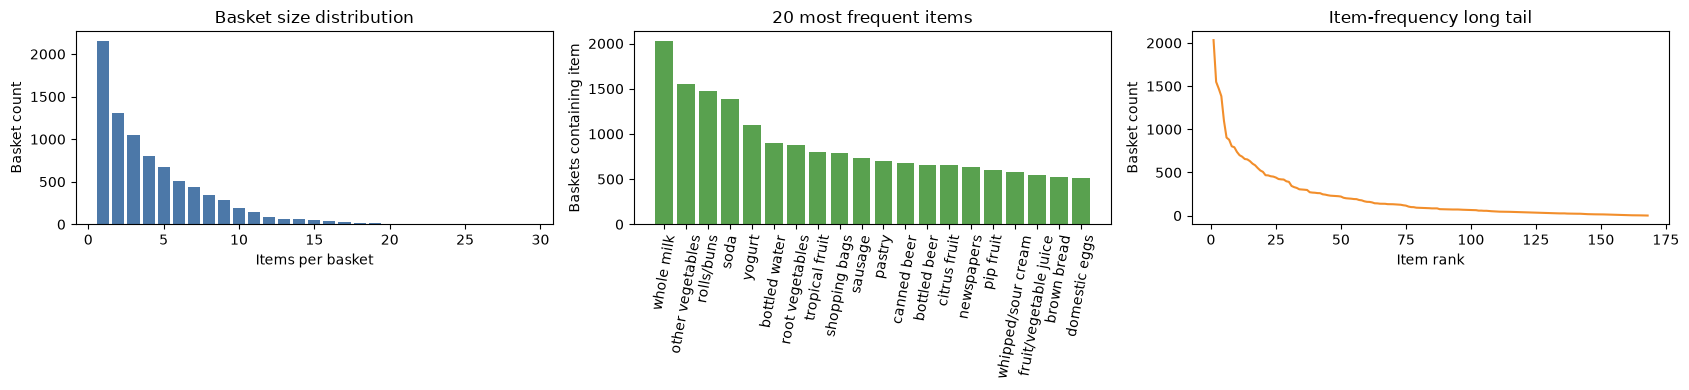

Test basket sizes describe visible items after target removal, not original basket sizes.


In [39]:
train=load_split('groceries_train.csv', EXPECTED_TRAIN)
test=load_split('groceries_test.csv', EXPECTED_TEST)
if set(train['basket_id']) & set(test['basket_id']):
    raise ValueError('basket_id bị giao giữa train và test.')
if any(TARGET in basket for basket in test['items_list']):
    raise ValueError('Tệp test có target; dừng để kiểm tra dữ liệu được cấp.')

# Chuẩn bị giỏ hàng và ma trận boolean
train_baskets=train['items_list'].tolist()
test_baskets=test['items_list'].tolist()
train_vocab=sorted({item for basket in train_baskets for item in basket})
test_vocab={item for basket in test_baskets for item in basket}
all_vocab=set(train_vocab) | test_vocab
train_matrix=pd.DataFrame(item_matrix(train_baskets, train_vocab),
                          columns=train_vocab, index=train['basket_id'])
train_matrix.index.name='basket_id'
train['basket_size']=train_matrix.sum(axis=1).astype(int).to_numpy()
# thống kê số món trong tập test (sau khi loại bỏ mục tiêu)
summary=pd.DataFrame([
 {'split':'train','baskets':len(train),'distinct_items':len(train_vocab),
  'mean_size':train['basket_size'].mean(),'median_size':train['basket_size'].median(),
  'min_size':train['basket_size'].min(),'q25':train['basket_size'].quantile(.25),
  'q75':train['basket_size'].quantile(.75),'max_size':train['basket_size'].max()},
 {'split':'test_visible_after_target_removal','baskets':len(test),'distinct_items':len(test_vocab),
  'mean_size':test['basket_size'].mean(),'median_size':test['basket_size'].median(),
  'min_size':test['basket_size'].min(),'q25':test['basket_size'].quantile(.25),
  'q75':test['basket_size'].quantile(.75),'max_size':test['basket_size'].max()}])
display(summary.round(3))
print('Train Boolean matrix:',train_matrix.shape,
      '| row sums match basket sizes:',bool(np.array_equal(train_matrix.sum(axis=1),train['basket_size'])))
print('Vocabulary sizes: train=',len(train_vocab),', visible test=',len(test_vocab),
      ', union=',len(all_vocab),'; test-only items=',sorted(test_vocab-set(train_vocab)))
#20 mon hang pho bien nhat
top20=train_matrix.sum(axis=0).sort_values(ascending=False).head(20).rename('basket_count').reset_index()
top20.columns=['item','basket_count'];top20['support']=top20['basket_count']/len(train)
display(top20)
# ve bieu do thong ke
size_counts=train['basket_size'].value_counts().sort_index()
fig,axes=plt.subplots(1,3,figsize=(17,4))
axes[0].bar(size_counts.index,size_counts.values,color='#4c78a8')
axes[0].set(title='Basket size distribution',xlabel='Items per basket',ylabel='Basket count')
axes[1].bar(top20['item'],top20['basket_count'],color='#59a14f')
axes[1].tick_params(axis='x',rotation=80)
axes[1].set(title='20 most frequent items',ylabel='Baskets containing item')
all_frequency=train_matrix.sum(axis=0).sort_values(ascending=False)
axes[2].plot(np.arange(1,len(all_frequency)+1),all_frequency.to_numpy(),color='#f28e2b')
axes[2].set(title='Item-frequency long tail',xlabel='Item rank',ylabel='Basket count')
plt.tight_layout();plt.show()
print('Test basket sizes describe visible items after target removal, not original basket sizes.')

### 1b. Kiểm tra chất lượng dữ liệu
Đo giỏ một món, giỏ lớn (dùng ngưỡng Tukey), nội dung giỏ trùng, món lặp, khoảng trắng và nhãn/cặp tên cần rà soát. Các cặp gần tên là ứng viên kiểm tra thủ công, không mặc định là đồng nghĩa. Không tự xóa giao dịch.

In [40]:
# kiểm tra chất lượng dữ liệu
sizes=train['basket_size'];q1,q3=sizes.quantile([.25,.75]);upper_fence=q3+1.5*(q3-q1)
content_keys=[tuple(sorted(basket)) for basket in train_baskets]
duplicate_content_excess=len(content_keys)-len(set(content_keys))
raw_tokens=[token for value in train['items'] for token in value.split(';')]
whitespace_tokens=sum(token!=token.strip() for token in raw_tokens)

# danh sách các cặp tên tương tự để xem xét thủ công, không phải là tuyên bố rằng chúng là đồng nghĩa
near_name_candidates=[
 ('cream','whipped/sour cream'),('cream cheese','soft cheese'),('curd','curd cheese'),
 ('canned beer','bottled beer'),('liquor','liqueur'),('prosecco','sparkling wine'),
 ('frozen fruits','berries'),('frozen vegetables',TARGET),('whole milk','UHT-milk'),
 ('fruit/vegetable juice','misc. beverages')]

# Tạo bảng chất lượng dữ liệu
near_name_candidates=[pair for pair in near_name_candidates if set(pair)<=all_vocab]
uppercase_labels=sorted(item for item in all_vocab if any(char.isupper() for char in item))
quality=pd.DataFrame([
 {'issue':'Single-item train baskets','count':int(sizes.eq(1).sum()),'denominator':len(train),
  'measurement':f'{sizes.eq(1).mean():.2%}; retained, not automatically removed.'},
 {'issue':'Very large train baskets','count':int(sizes.gt(upper_fence).sum()),'denominator':len(train),
  'measurement':f'Size > Tukey upper fence {upper_fence:.2f}; inspect, do not auto-delete.'},
 {'issue':'Repeated item within a basket','count':0,'denominator':len(train),
  'measurement':'Parser checks every basket and would stop if a repeated item were found.'},
 {'issue':'Duplicate basket contents beyond first','count':duplicate_content_excess,'denominator':len(train),
  'measurement':'Order-insensitive identical item sets; distinct IDs are retained.'},
 {'issue':'Similar-name pairs for manual review','count':len(near_name_candidates),'denominator':len(all_vocab),
  'measurement':'; '.join(f'{a} / {b}' for a,b in near_name_candidates)},
 {'issue':'Tokens with boundary whitespace','count':whitespace_tokens,'denominator':len(raw_tokens),
  'measurement':'Counted before trimming parsed items.'},
 {'issue':'Labels containing uppercase characters','count':len(uppercase_labels),'denominator':len(all_vocab),
  'measurement':'Preserve original spelling; inspect: '+', '.join(uppercase_labels)},
 {'issue':'Train/test basket_id overlap','count':len(set(train.basket_id)&set(test.basket_id)),
  'denominator':len(test),'measurement':'Must be zero.'}
])
quality['rate_percent']=100*quality['count']/quality['denominator']
display(quality)
print('Similar-name entries are review candidates, not claims that labels are synonyms.')

,issue,count,denominator,measurement,rate_percent
0,Single-item train baskets,2159,8300,"26.01%; retained, not automatically removed.",26.012048
1,Very large train baskets,231,8300,"Size > Tukey upper fence 13.50; inspect, do no...",2.783133
2,Repeated item within a basket,0,8300,Parser checks every basket and would stop if a...,0.000000
3,Duplicate basket contents beyond first,2608,8300,Order-insensitive identical item sets; distinc...,31.421687
4,Similar-name pairs for manual review,10,169,cream / whipped/sour cream; cream cheese / sof...,5.917160
5,Tokens with boundary whitespace,0,35223,Counted before trimming parsed items.,0.000000
6,Labels containing uppercase characters,2,169,Preserve original spelling; inspect: Instant f...,1.183432
7,Train/test basket_id overlap,0,1535,Must be zero.,0.000000


Similar-name entries are review candidates, not claims that labels are synonyms.


### 1c. Tỷ lệ `other vegetables` và ảnh hưởng chọn mẫu
So sánh tỷ lệ trên toàn bộ train với train có kích thước giỏ gốc ≥2. Đây là quần thể phù hợp hơn để mô phỏng cách lấy test và đánh giá/chọn ngưỡng; không dùng để suy ra prevalence hoặc nhãn của test.

In [41]:
# tính toán tỷ lệ dương tính trong tập train và tập eligible (giỏ hàng >= 2 món)
# mục tiêu là "other vegetables" trong tập train, và tập test chỉ chứa các giỏ hàng có ít nhất 2 món.
# mục đích là đánh giá hiệu suất mô hình trên tập hợp các giỏ hàng có chứa mục tiêu
train_target=train_matrix[TARGET].astype(bool)
eligible=train['basket_size'].ge(2).to_numpy()
prevalence=pd.DataFrame([
 {'population':'All train baskets','baskets':int(len(train)),
  'target_positive':int(train_target.sum()),'prevalence':float(train_target.mean())},
 {'population':'Train; original basket size >= 2','baskets':int(eligible.sum()),
  'target_positive':int(train_target[eligible].sum()),'prevalence':float(train_target[eligible].mean())}
])
prevalence['prevalence_percent']=100*prevalence['prevalence']
display(prevalence.round(4))
delta=prevalence.loc[1,'prevalence']-prevalence.loc[0,'prevalence']
print(f"The eligible-basket prevalence differs from all-train prevalence by {delta:.4f} "
      f"({delta*100:.2f} percentage points). Use the eligible population for validation "
      'and threshold discussion; do not treat it as hidden test prevalence.')

,population,baskets,target_positive,prevalence,prevalence_percent
0,All train baskets,8300,1549,0.1866,18.6627
1,Train; original basket size >= 2,6141,1487,0.2421,24.2143


The eligible-basket prevalence differs from all-train prevalence by 0.0555 (5.55 percentage points). Use the eligible population for validation and threshold discussion; do not treat it as hidden test prevalence.


### 1d. item_group_rules 169 món và phương án thay thế
Ánh xạ mỗi món vào đúng một nhóm (ít nhất 15 nhóm), lưu thành CSV riêng và nêu các trường hợp còn tranh cãi. Tác động của phương án thay thế lên luật kết hợp thuộc Phần 2/WBS 3.5, không kết luận ở đây.

In [ ]:
# 23 nhóm món
item_group_rules={'bakery_bread': ('brown bread',
                  'cake bar',
                  'long life bakery product',
                  'pastry',
                  'roll products',
                  'rolls/buns',
                  'semi-finished bread',
                  'waffles',
                  'white bread',
                  'zwieback'),
 'dairy_eggs': ('UHT-milk',
                'butter',
                'butter milk',
                'condensed milk',
                'cream',
                'cream cheese',
                'curd',
                'curd cheese',
                'domestic eggs',
                'hard cheese',
                'margarine',
                'processed cheese',
                'sliced cheese',
                'soft cheese',
                'specialty cheese',
                'spread cheese',
                'whipped/sour cream',
                'whole milk',
                'yogurt'),
 'meat_poultry': ('beef',
                  'chicken',
                  'frankfurter',
                  'ham',
                  'hamburger meat',
                  'liver loaf',
                  'meat',
                  'organic sausage',
                  'pork',
                  'sausage',
                  'turkey'),
 'fish_seafood': ('fish', 'frozen fish'),
 'fresh_fruit': ('berries', 'citrus fruit', 'grapes', 'pip fruit', 'tropical fruit'),
 'fresh_vegetables': ('onions',
                      'other vegetables',
                      'potato products',
                      'root vegetables',
                      'specialty vegetables'),
 'packaged_produce': ('packaged fruit/vegetables',),
 'frozen_foods': ('frozen chicken',
                  'frozen dessert',
                  'frozen fruits',
                  'frozen meals',
                  'frozen potato products',
                  'frozen vegetables',
                  'ice cream'),
 'nonalcoholic_beverages': ('beverages',
                            'bottled water',
                            'cocoa drinks',
                            'coffee',
                            'fruit/vegetable juice',
                            'instant coffee',
                            'misc. beverages',
                            'soda',
                            'tea'),
 'alcoholic_beverages': ('bottled beer',
                         'brandy',
                         'canned beer',
                         'liqueur',
                         'liquor',
                         'liquor (appetizer)',
                         'prosecco',
                         'red/blush wine',
                         'rum',
                         'sparkling wine',
                         'whisky',
                         'white wine'),
 'pantry_baking_grains': ('Instant food products',
                          'baking powder',
                          'cereals',
                          'flour',
                          'pasta',
                          'pudding powder',
                          'rice',
                          'sugar'),
 'condiments_cooking': ('herbs',
                        'ketchup',
                        'mayonnaise',
                        'mustard',
                        'oil',
                        'salad dressing',
                        'salt',
                        'sauces',
                        'specialty fat',
                        'spices',
                        'vinegar'),
 'canned_preserved': ('canned fish',
                      'canned fruit',
                      'canned vegetables',
                      'jam',
                      'pickled vegetables',
                      'preservation products',
                      'sweet spreads'),
 'snacks_sweets': ('candy',
                   'chewing gum',
                   'chocolate',
                   'chocolate marshmallow',
                   'cooking chocolate',
                   'honey',
                   'nut snack',
                   'nuts/prunes',
                   'popcorn',
                   'salty snack',
                   'snack products',
                   'specialty bar',
                   'specialty chocolate',
                   'syrup',
                   'tidbits'),
 'ready_to_eat_meals': ('dessert',
                        'finished products',
                        'meat spreads',
                        'ready soups',
                        'soups'),
 'baby_products': ('baby cosmetics', 'baby food'),
 'pet_products': ('cat food', 'dog food', 'pet care'),
 'household_cleaning': ('abrasive cleaner',
                        'bathroom cleaner',
                        'cleaner',
                        'decalcifier',
                        'detergent',
                        'dish cleaner',
                        'house keeping products',
                        'rubbing alcohol',
                        'softener',
                        'toilet cleaner'),
 'personal_care_hygiene': ('dental care',
                           'female sanitary products',
                           'hair spray',
                           'hygiene articles',
                           'make up remover',
                           'male cosmetics',
                           'skin care',
                           'soap'),
 'household_kitchen': ('bags',
                       'candles',
                       'cling film/bags',
                       'cookware',
                       'dishes',
                       'kitchen towels',
                       'kitchen utensil',
                       'light bulbs',
                       'napkins',
                       'shopping bags'),
 'garden_plants': ('flower (seeds)', 'flower soil/fertilizer', 'pot plants'),
 'media_stationery': ('newspapers', 'photo/film', 'sound storage medium'),
 'specialty_miscellaneous': ('artif. sweetener', 'organic products', 'seasonal products')}
AMBIGUOUS_ITEMS={'frozen dessert': ('frozen_foods',
                    'dairy_eggs',
                    'Frozen form is used for the primary group; a dairy/dessert group assignment '
                    'is also plausible.'),
 'packaged fruit/vegetables': ('packaged_produce',
                               'fresh_vegetables',
                               'Kept separate because packaging may indicate mixed or '
                               'processed produce.'),
 'finished products': ('ready_to_eat_meals',
                       'pantry_baking_grains',
                       'The source label is broad; ready-to-eat is a practical but '
                       'uncertain interpretation.'),
 'meat spreads': ('ready_to_eat_meals',
                  'meat_poultry',
                  'Could be classified by ingredient (meat) or use '
                  '(spread/ready-to-eat).'),
 'rubbing alcohol': ('household_cleaning',
                     'personal_care_hygiene',
                     'May be a household cleaner or a personal-care/first-aid product.'),
 'flower (seeds)': ('garden_plants',
                    'pantry_baking_grains',
                    'The category label is interpreted as seeds for planting, not food '
                    'seeds.'),
 'organic products': ('specialty_miscellaneous',
                      'fresh_vegetables',
                      'Organic is a production attribute rather than a product type; '
                      'item identity is unspecified.'),
 'seasonal products': ('specialty_miscellaneous',
                       'fresh_fruit',
                       'Seasonality does not identify a specific product class.'),
 'misc. beverages': ('nonalcoholic_beverages',
                     'specialty_miscellaneous',
                     'The source label does not specify beverage type; a specialty '
                     'grouping is also plausible.'),
 'specialty fat': ('condiments_cooking',
                   'dairy_eggs',
                   'Grouped by cooking use; product composition is not specified.'),
 'margarine': ('dairy_eggs',
               'condiments_cooking',
               'A butter substitute; may be grouped with dairy-case spreads or cooking '
               'fats.'),
 'potato products': ('fresh_vegetables',
                     'pantry_baking_grains',
                     'Primary grouping follows the potato ingredient; the label may '
                     'refer to a processed shelf-stable product.'),
 'syrup': ('snacks_sweets',
           'nonalcoholic_beverages',
           'Could be a sweet spread/topping or a drink ingredient.'),
 'nut snack': ('snacks_sweets',
               'fresh_fruit',
               'Grouped by snack use, although nuts are botanically distinct from '
               'fruit.'),
 'nuts/prunes': ('snacks_sweets',
                 'fresh_fruit',
                 'The label combines nuts and dried fruit; grouped by likely packaged '
                 'snack use.'),
 'long life bakery product': ('bakery_bread',
                              'pantry_baking_grains',
                              'Shelf-stable bakery is grouped by product type, not '
                              'storage life.')}

# tạo bảng tra ngược từ tên món → mã nhóm
ITEM_TO_GROUP={item:group for group,items in item_group_rules.items() for item in items}
# đổi mã nhóm thành tên nhóm dễ đọc
GROUP_NAMES={
'bakery_bread':'Bakery and bread','dairy_eggs':'Dairy and eggs','meat_poultry':'Meat and poultry',
'fish_seafood':'Fish and seafood','fresh_fruit':'Fresh fruit','fresh_vegetables':'Fresh vegetables',
'packaged_produce':'Packaged fruit and vegetables','frozen_foods':'Frozen foods',
'nonalcoholic_beverages':'Non-alcoholic beverages','alcoholic_beverages':'Alcoholic beverages',
'pantry_baking_grains':'Pantry, baking and grains','condiments_cooking':'Condiments and cooking ingredients',
'canned_preserved':'Canned and preserved foods','snacks_sweets':'Snacks and sweets',
'ready_to_eat_meals':'Ready-to-eat foods and soups','baby_products':'Baby products','pet_products':'Pet products',
'household_cleaning':'Household cleaning','personal_care_hygiene':'Personal care and hygiene',
'household_kitchen':'Household and kitchen','garden_plants':'Garden and plants',
'media_stationery':'Media and stationery','specialty_miscellaneous':'Specialty and miscellaneous groceries'}

# kiểm tra và lưu bảng phân nhóm
if set(ITEM_TO_GROUP)!=all_vocab:
    raise ValueError(f'item_group_rules must exactly cover observed items. Missing={all_vocab-set(ITEM_TO_GROUP)}; extra={set(ITEM_TO_GROUP)-all_vocab}')
if len(ITEM_TO_GROUP)!=sum(len(items) for items in item_group_rules.values()):
    raise ValueError('An item appears in more than one primary group.')
if len(item_group_rules)<15:
    raise ValueError('Assignment requires at least 15 product groups.')
mapping=pd.DataFrame([
 {'item':item,'group':ITEM_TO_GROUP[item],'group_name':GROUP_NAMES[ITEM_TO_GROUP[item]]}
 for item in sorted(ITEM_TO_GROUP)])
print(f"Mapping coverage: {mapping['item'].nunique()} items in {mapping['group'].nunique()} groups.")
display(mapping.groupby(['group','group_name']).size().rename('item_count').reset_index())
alternatives=pd.DataFrame([
 {'item':item,'primary_group':ITEM_TO_GROUP[item],
  'alternative_group':alternative,'reason':reason}
 for item,(_primary,alternative,reason) in AMBIGUOUS_ITEMS.items() if item in ITEM_TO_GROUP])
print('Alternative assignments requiring group review:',len(alternatives))
display(alternatives)
mapping_dir=PROJECT_ROOT/'data'/'mappings';mapping_dir.mkdir(parents=True,exist_ok=True)
mapping.to_csv(mapping_dir/'item_to_group.csv',index=False)
alternatives.to_csv(mapping_dir/'item_group_alternatives.csv',index=False)
print('Saved item_to_group.csv and item_group_alternatives.csv under data/mappings/.')

Mapping coverage: 169 items in 23 groups.


,group,group_name,item_count
0,alcoholic_beverages,Alcoholic beverages,12
1,baby_products,Baby products,2
2,bakery_bread,Bakery and bread,10
3,canned_preserved,Canned and preserved foods,7
4,condiments_cooking,Condiments and cooking ingredients,11
5,dairy_eggs,Dairy and eggs,19
6,fish_seafood,Fish and seafood,2
7,fresh_fruit,Fresh fruit,5
8,fresh_vegetables,Fresh vegetables,5
9,frozen_foods,Frozen foods,7


Alternative assignments requiring group review: 16


,item,primary_group,alternative_group,reason
0,frozen dessert,frozen_foods,dairy_eggs,Frozen form is used for the primary group; a d...
1,packaged fruit/vegetables,packaged_produce,fresh_vegetables,Kept separate because packaging may indicate m...
2,finished products,ready_to_eat_meals,pantry_baking_grains,The source label is broad; ready-to-eat is a p...
3,meat spreads,ready_to_eat_meals,meat_poultry,Could be classified by ingredient (meat) or us...
4,rubbing alcohol,household_cleaning,personal_care_hygiene,May be a household cleaner or a personal-care/...
5,flower (seeds),garden_plants,pantry_baking_grains,The category label is interpreted as seeds for...
6,organic products,specialty_miscellaneous,fresh_vegetables,Organic is a production attribute rather than ...
7,seasonal products,specialty_miscellaneous,fresh_fruit,Seasonality does not identify a specific produ...
8,misc. beverages,nonalcoholic_beverages,specialty_miscellaneous,The source label does not specify beverage typ...
9,specialty fat,condiments_cooking,dairy_eggs,Grouped by cooking use; product composition is...


Saved item_to_group.csv and item_group_alternatives.csv under data/mappings/.


## 2. Mẫu thường xuyên và luật kết hợp

In [43]:
# TODO: Phần 2 do thành viên phụ trách luật kết hợp triển khai.

## 3. Phân lớp


In [44]:
# TODO: Phần 3 do thành viên phụ trách phân lớp triển khai.

## 4. Phân cụm


In [45]:
# TODO: Phần 4 do thành viên phụ trách phân cụm triển khai.

## 5. Phát hiện giỏ hàng bất thường


In [46]:
# TODO: Phần 5 do thành viên phụ trách phát hiện bất thường triển khai.

## 6. Phản biện, rủi ro và xu hướng


In [47]:
# TODO: Hoàn thiện Phần 6 sau khi có kết quả các phần của nhóm.